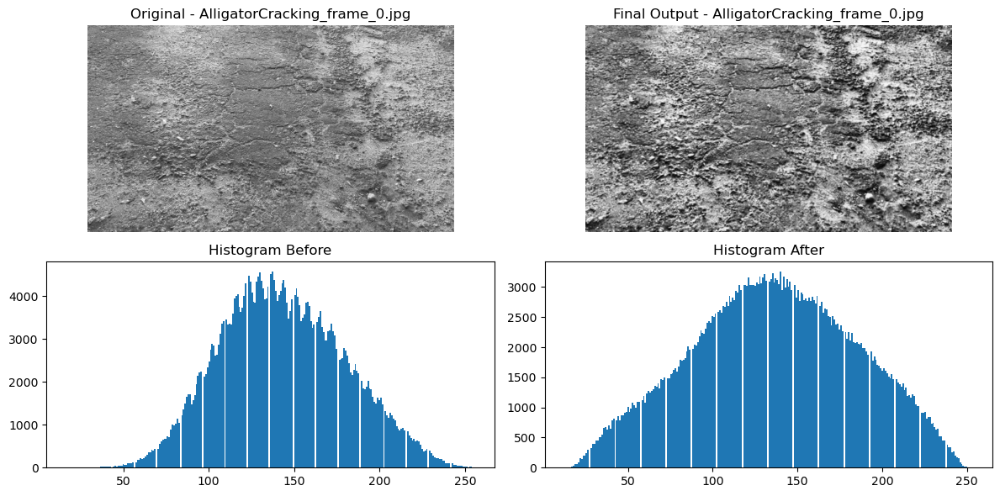

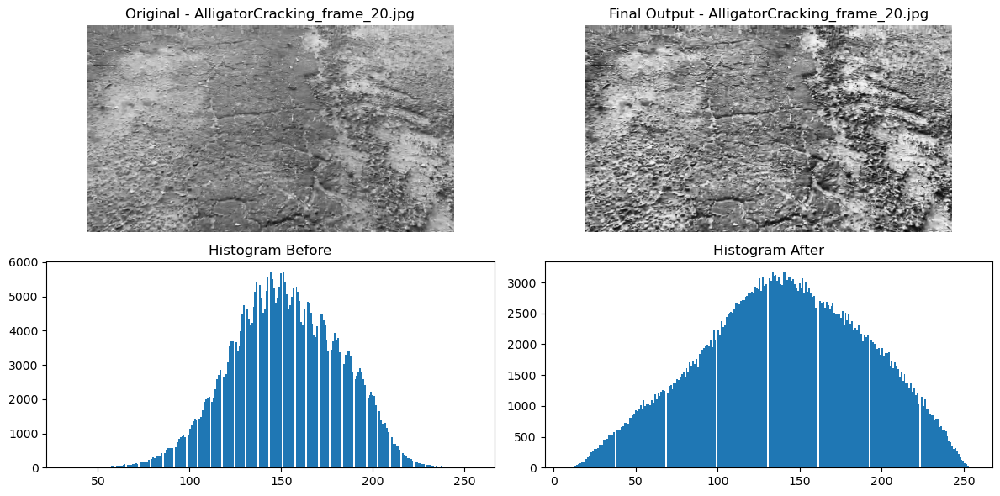

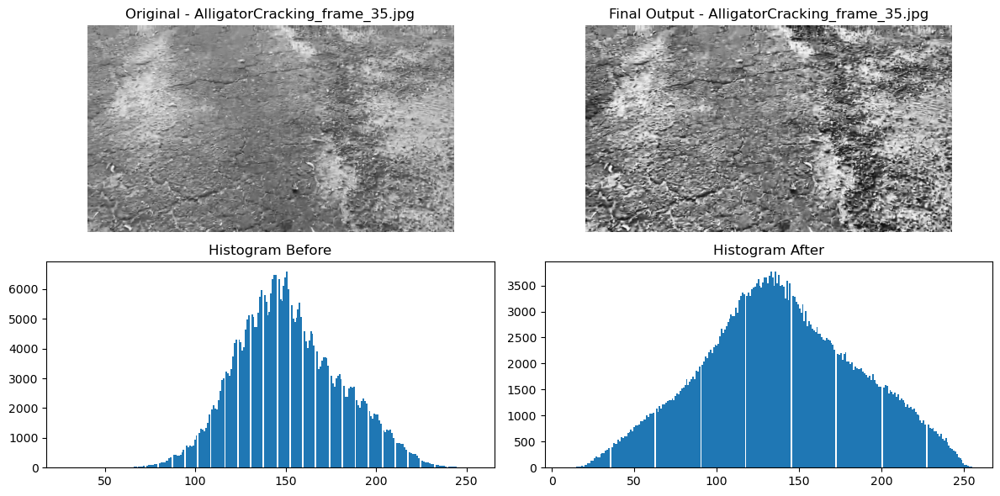

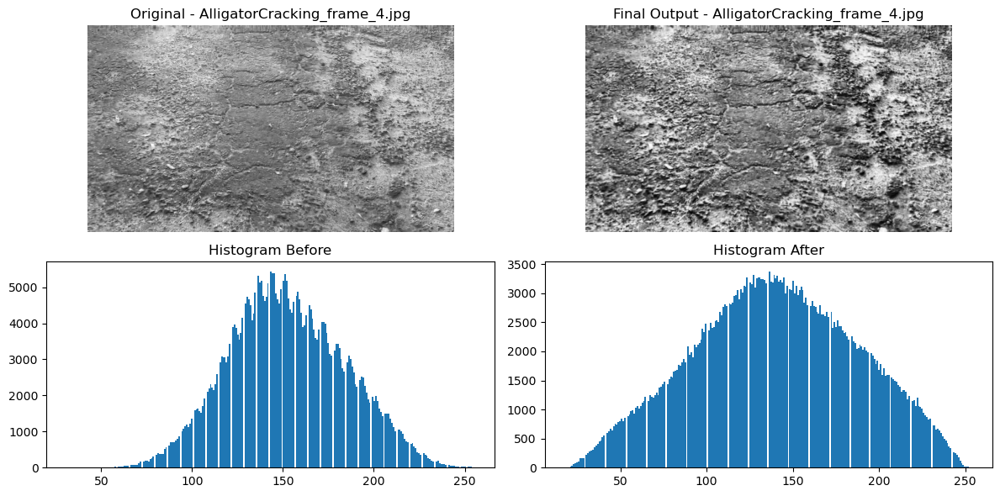

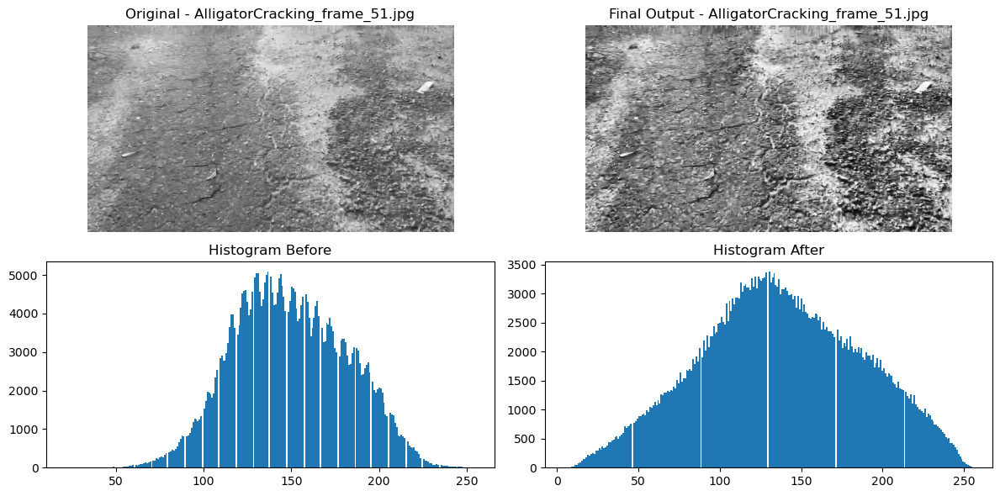

...

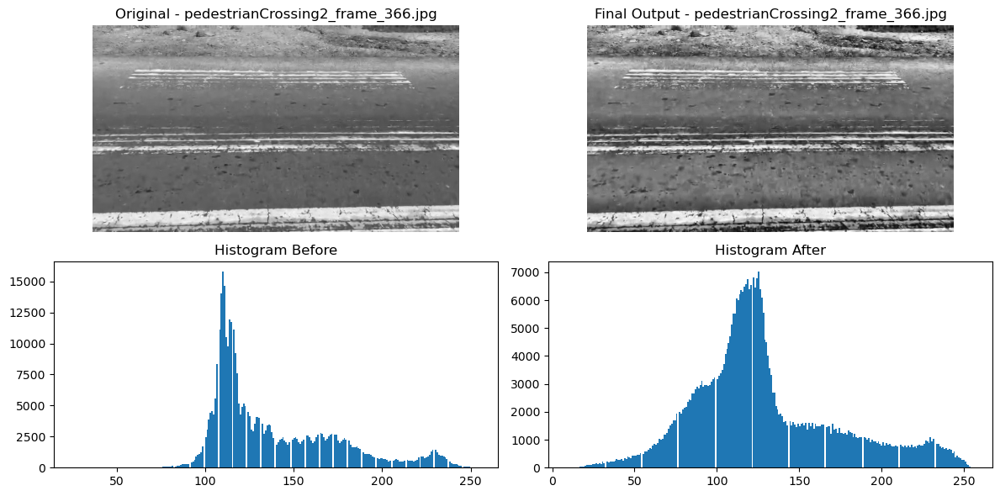

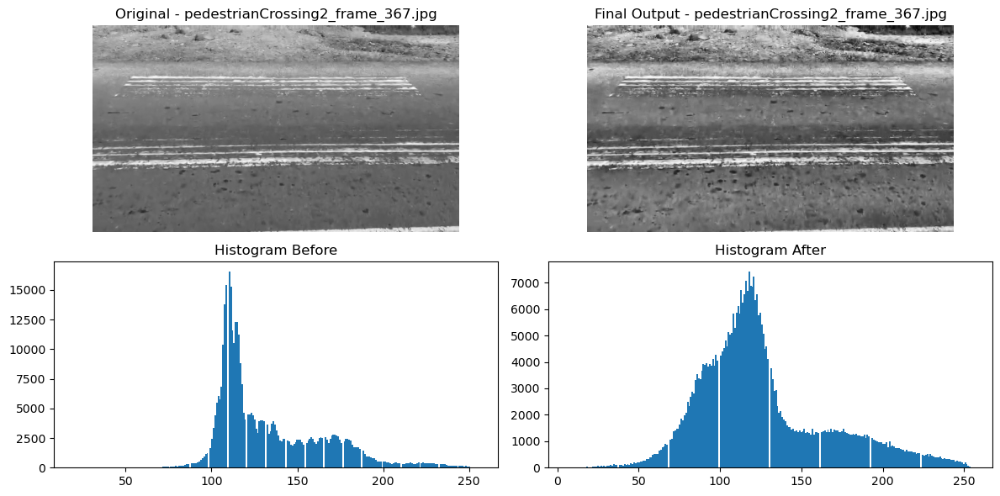

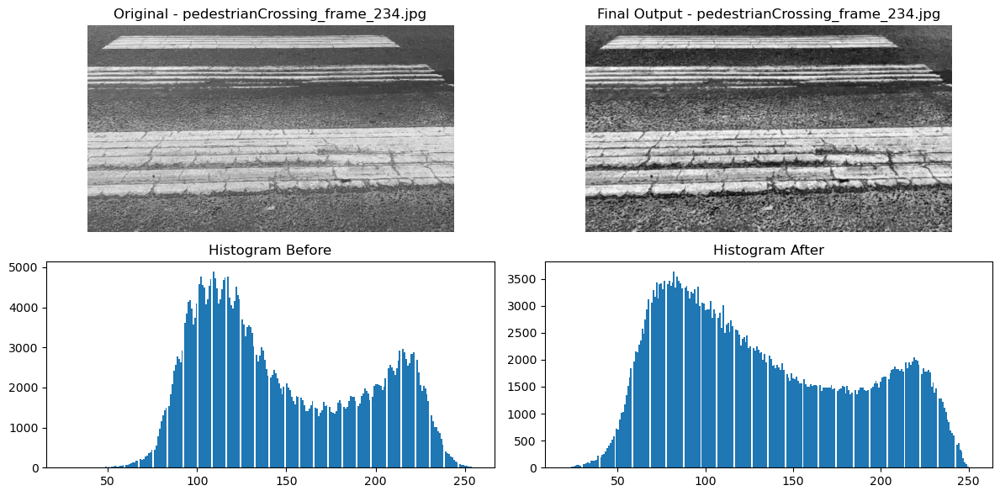

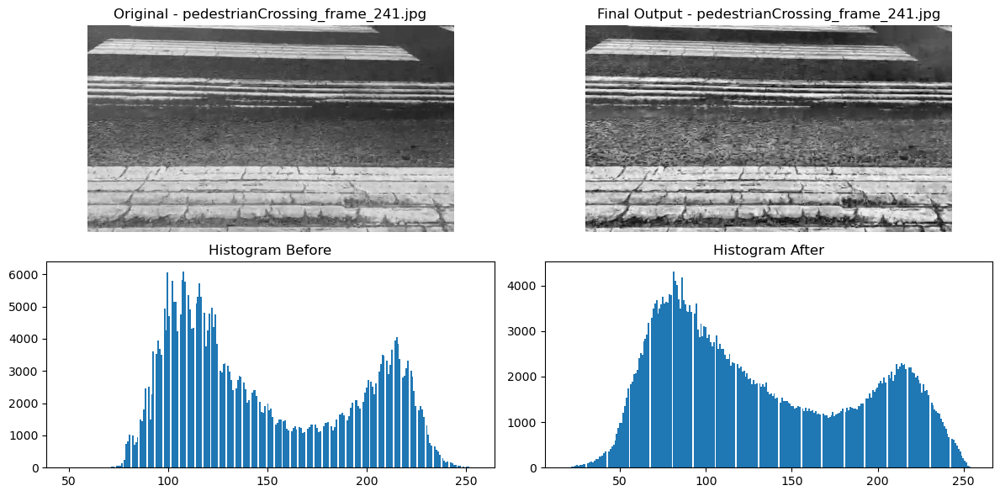

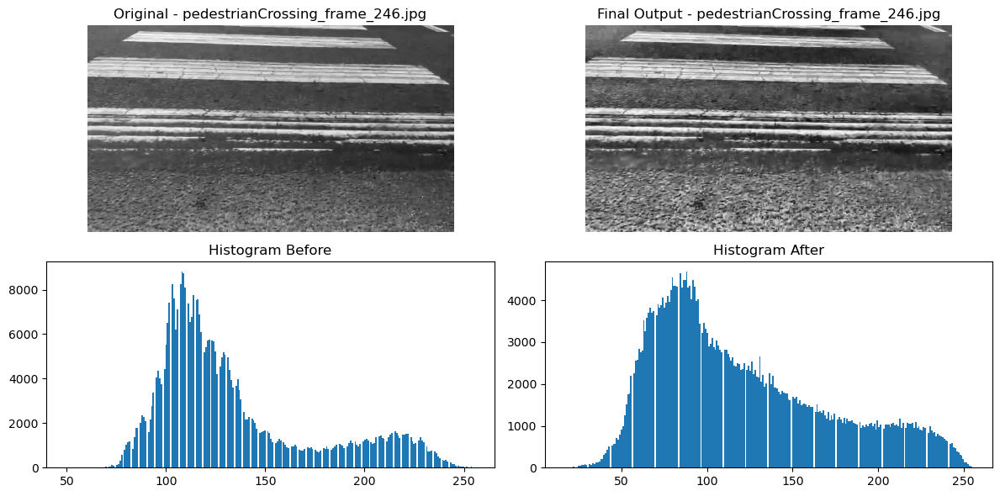


================ FINAL PIPELINE ANALYSIS TABLE ================

                            Frame NoiseType    Level  Blur  BrightB  BrightA  ContB  ContA  SharpB  SharpA
    AlligatorCracking_frame_0.jpg  Gaussian Moderate Clear    143.5    136.1   36.3   48.4  7218.1  1749.3
   AlligatorCracking_frame_20.jpg       Low      Low Clear    152.6    140.1   29.7   49.7   698.7  2706.4
   AlligatorCracking_frame_35.jpg       Low      Low Clear    151.6    138.3   28.7   46.8   557.5  2147.9
    AlligatorCracking_frame_4.jpg  Gaussian Moderate Clear    152.3    140.0   31.9   47.2  1111.6  1072.3
   AlligatorCracking_frame_51.jpg       Low      Low Clear    149.5    137.2   32.1   49.4   565.1  2150.5
    AlligatorCracking_frame_9.jpg       Low      Low Clear    150.6    137.7   30.8   50.3   841.7  3137.4
       EdgeCracking3_frame_72.jpg       Low      Low Clear    154.2    142.5   24.2   43.0   568.9  2438.2
      EdgeCracking4_frame_123.jpg       Low      Low Clear    143.0    136.3  

In [2]:
import cv2
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt

input_folder = "frames"

os.makedirs("output/original_gray", exist_ok=True)
os.makedirs("output/denoised", exist_ok=True)
os.makedirs("output/clahe", exist_ok=True)
os.makedirs("output/final", exist_ok=True)


def show_results(original, processed, file_name):

    plt.figure(figsize=(12,6))

    plt.subplot(2,2,1)
    plt.imshow(original, cmap='gray')
    plt.title("Original - " + file_name)
    plt.axis('off')

    plt.subplot(2,2,2)
    plt.imshow(processed, cmap='gray')
    plt.title("Final Output - " + file_name)
    plt.axis('off')

    plt.subplot(2,2,3)
    plt.hist(original.ravel(), bins=256)
    plt.title("Histogram Before")

    plt.subplot(2,2,4)
    plt.hist(processed.ravel(), bins=256)
    plt.title("Histogram After")

    plt.tight_layout()
    plt.show()


def estimate_noise_variance(gray):
    blur = cv2.GaussianBlur(gray, (5,5), 0)
    noise = gray.astype(np.float32) - blur.astype(np.float32)
    return np.var(noise)

def detect_salt_pepper(gray, threshold=0.01):
    total_pixels = gray.size
    extreme_pixels = np.sum((gray == 0) | (gray == 255))
    return (extreme_pixels / total_pixels) > threshold

def apply_clahe(gray):
    clahe = cv2.createCLAHE(clipLimit=1.8, tileGridSize=(8,8))
    return clahe.apply(gray)

def laplacian_variance(img):
    return cv2.Laplacian(img, cv2.CV_64F).var()


files = sorted(os.listdir(input_folder))
analysis_data = []

for file in files:

    if not file.lower().endswith((".jpg",".png",".jpeg")):
        continue

    path = os.path.join(input_folder, file)
    img = cv2.imread(path)

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    noise_var = estimate_noise_variance(gray)
    sp_noise = detect_salt_pepper(gray)
    sharpness = laplacian_variance(gray)

    analysis_data.append([file, noise_var, sp_noise, sharpness])

df = pd.DataFrame(analysis_data,
                  columns=["Frame","NoiseVariance","SaltPepper","Sharpness"])

mean_noise = df["NoiseVariance"].mean()
mean_sharp = df["Sharpness"].mean()

df["NoiseLevel"] = df["NoiseVariance"].apply(
    lambda x: "Low" if x < mean_noise else "Moderate"
)

blur_threshold = mean_sharp * 0.7


results = []

noise_before_list = []
noise_after_list = []

contrast_before_list = []
contrast_after_list = []

sharp_before_list = []
sharp_after_list = []

for index, row in df.iterrows():

    file = row["Frame"]
    path = os.path.join(input_folder, file)
    img = cv2.imread(path)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    cv2.imwrite(f"output/original_gray/{file}", gray)

    noise_before = estimate_noise_variance(gray)
    contrast_before = np.std(gray)
    sharp_before = laplacian_variance(gray)

    if row["NoiseLevel"] == "Moderate":

        if row["SaltPepper"]:
            denoised = cv2.medianBlur(gray, 3)
            noise_type = "Salt & Pepper"
        else:
            denoised = cv2.GaussianBlur(gray, (3,3), 0)
            noise_type = "Gaussian"
    else:
        denoised = gray.copy()
        noise_type = "Low"

    cv2.imwrite(f"output/denoised/{file}", denoised)

    noise_after = estimate_noise_variance(denoised)

    contrast_img = apply_clahe(denoised)

    cv2.imwrite(f"output/clahe/{file}", contrast_img)

    sharpness_value = laplacian_variance(contrast_img)

    if sharpness_value < blur_threshold:
        kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
        final = cv2.filter2D(contrast_img, -1, kernel)
        blur_status = "Blurred"
    else:
        final = contrast_img.copy()
        blur_status = "Clear"

    cv2.imwrite(f"output/final/{file}", final)

    contrast_after = np.std(final)
    sharp_after = laplacian_variance(final)

    noise_before_list.append(noise_before)
    noise_after_list.append(noise_after)

    contrast_before_list.append(contrast_before)
    contrast_after_list.append(contrast_after)

    sharp_before_list.append(sharp_before)
    sharp_after_list.append(sharp_after)

    results.append([
        file,
        noise_type,
        row["NoiseLevel"],
        blur_status,
        round(np.mean(gray),1),
        round(np.mean(final),1),
        round(contrast_before,1),
        round(contrast_after,1),
        round(sharp_before,1),
        round(sharp_after,1)
    ])

    show_results(gray, final, file)



print("\n================ FINAL PIPELINE ANALYSIS TABLE ================\n")

header = ["Frame","NoiseType","Level","Blur",
          "BrightB","BrightA",
          "ContB","ContA",
          "SharpB","SharpA"]

table_df = pd.DataFrame(results, columns=header)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

print(table_df.to_string(index=False))

def percent_change(before, after):
    before = np.mean(before)
    after = np.mean(after)
    return ((before - after) / before) * 100


print("\n================ OVERALL IMPROVEMENT SUMMARY ================\n")

print(f"Noise Reduction: {percent_change(noise_before_list, noise_after_list):.2f}%")
print(f"Contrast Change: {np.mean(contrast_after_list) - np.mean(contrast_before_list):.2f}")
print(f"Sharpness Change: {np.mean(sharp_after_list) - np.mean(sharp_before_list):.2f}")

print("\nPipeline Completed")